In [1]:
%% MIT 18.03 Lecture 16: Frequency Response, Nyquist Circle & Suspension Dynamics
% Description: Simulates multi-system frequency responses using Control System Toolbox:
%              1) Bode magnitude & phase of Dashpot-driven (band-pass) vs. Car Suspension.
%              2) Nyquist circle validation: |H(w) - 0.5| = 0.5 for dashpot-driven system.
%              3) Time-domain tracking of 1st-order tide model verifying extrema intersection x = y.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, bode, nyquist, lsim).
%
% % MBD Concept Mapping: Demonstrates continuous frequency response G(jw) as Complex Gain H(w).
% %                      Highlights that dashpot resonant peak wr = wn is invariant to damping b,
% %                      and confirms passive system circular locus on the Nyquist plane.


clear; clc; close all;


%% =========================================================================
%% Part 1: Second-Order Systems (Dashpot vs. Car Suspension) via Control Toolbox
%% =========================================================================
m = 1.0;            % Inertia / Mass (kg)
k = 4.0;            % Stiffness (N/m) -> wn = sqrt(k/m) = 2.0 rad/s
wn = sqrt(k / m);
b_nominal = 1.0;    % Damping constant (N*s/m)
b_light   = 0.3;    % Light damping to demonstrate sharp resonance peak


% 1. Dashpot-Driven System: G_dash(s) = (b*s) / (m*s^2 + b*s + k)
G_dash_nom   = tf([b_nominal, 0], [m, b_nominal, k]);
G_dash_light = tf([b_light,   0], [m, b_light,   k]);


% 2. Full Automobile Suspension: G_susp(s) = (b*s + k) / (m*s^2 + b*s + k)
G_susp = tf([b_nominal, k], [m, b_nominal, k]);


fprintf('=== Plant Transfer Functions (Control System Toolbox) ===\n');

=== Plant Transfer Functions (Control System Toolbox) ===

In [2]:
fprintf('Dashpot-Driven (Nominal)  : \n'); display(G_dash_nom);

Dashpot-Driven (Nominal)  : 
G_dash_nom =
 
       s
  -----------
  s^2 + s + 4
 
Continuous-time transfer function.
Model Properties

In [3]:
fprintf('Dashpot-Driven (Light Damping): \n'); display(G_dash_light);

Dashpot-Driven (Light Damping): 
G_dash_light =
 
       0.3 s
  ---------------
  s^2 + 0.3 s + 4
 
Continuous-time transfer function.
Model Properties

In [4]:
fprintf('Automobile Suspension     : \n'); display(G_susp);

Automobile Suspension     : 
G_susp =
 
     s + 4
  -----------
  s^2 + s + 4
 
Continuous-time transfer function.
Model Properties

In [5]:
fprintf('Theoretical Resonant Freq : wr = wn = %.4f rad/s\n', wn);

Theoretical Resonant Freq : wr = wn = 2.0000 rad/s

In [6]:
fprintf('=========================================================\n\n');


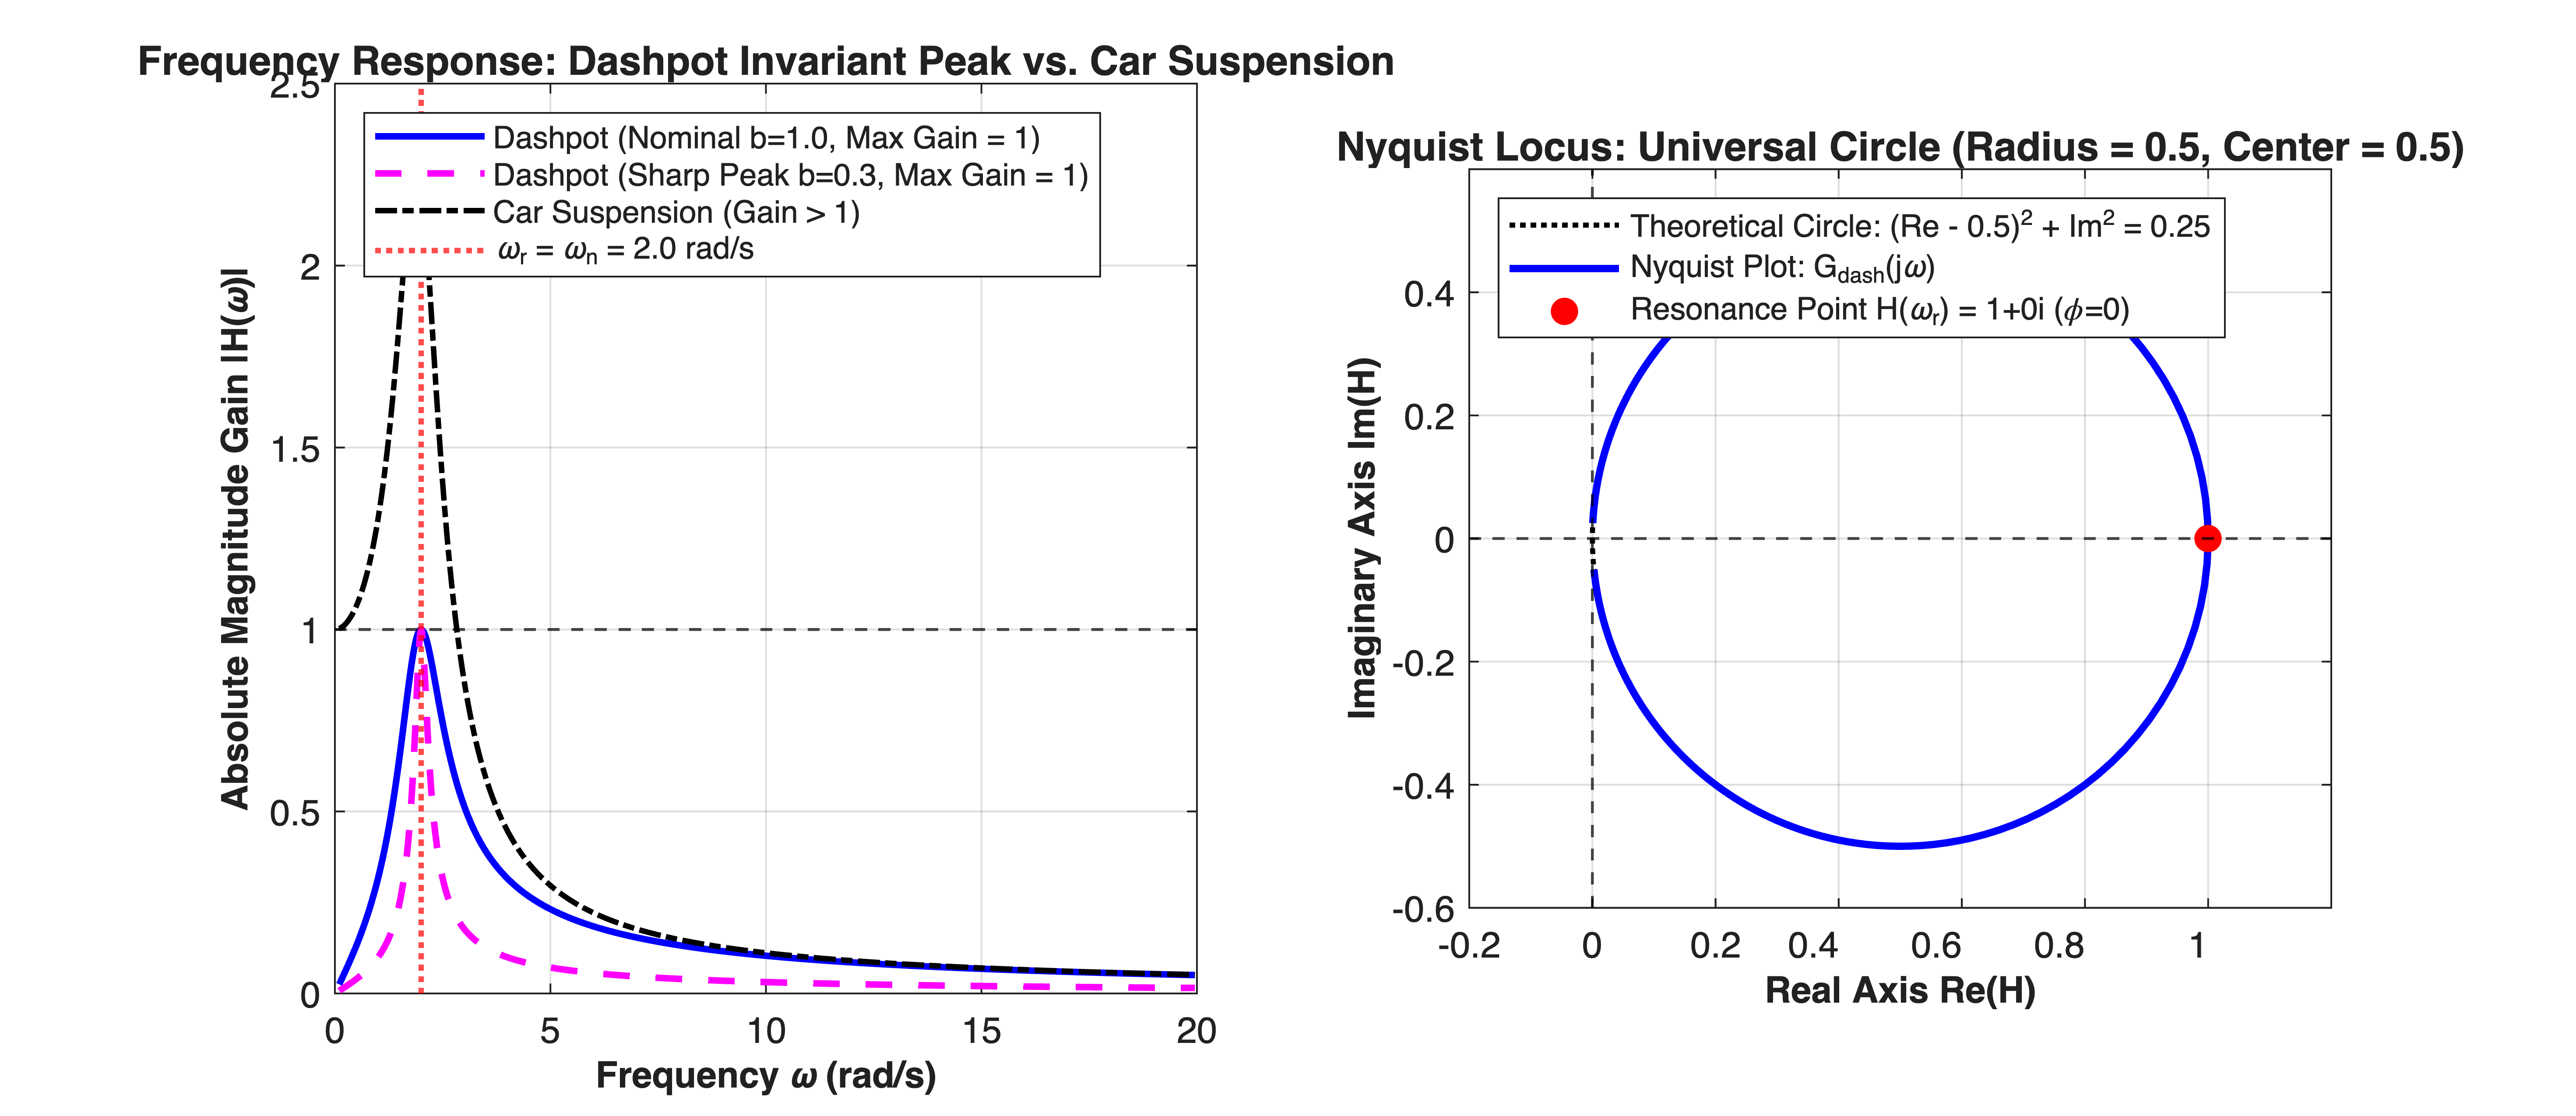

In [7]:


figure('Color', [1 1 1], 'Position', [80, 80, 1200, 520]);


% Subplot 1: Bode Magnitude & Phase Comparison
subplot(1, 2, 1);
w_vec = logspace(-1, 1.3, 600);
[mag_nom, phase_nom]     = bode(G_dash_nom, w_vec);
[mag_light, phase_light] = bode(G_dash_light, w_vec);
[mag_susp, phase_susp]   = bode(G_susp, w_vec);


mag_nom_lin   = squeeze(mag_nom);
mag_light_lin = squeeze(mag_light);
mag_susp_lin  = squeeze(mag_susp);


hold on; grid on; box on;
semilogx(w_vec, mag_nom_lin, 'b-', 'LineWidth', 1.8, ...
         'DisplayName', 'Dashpot (Nominal b=1.0, Max Gain = 1)');
semilogx(w_vec, mag_light_lin, 'm--', 'LineWidth', 1.8, ...
         'DisplayName', 'Dashpot (Sharp Peak b=0.3, Max Gain = 1)');
semilogx(w_vec, mag_susp_lin, 'k-.', 'LineWidth', 1.5, ...
         'DisplayName', 'Car Suspension (Gain > 1)');


xline(wn, 'r:', 'LineWidth', 1.5, 'DisplayName', '\omega_r = \omega_n = 2.0 rad/s');
yline(1.0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


xlabel('Frequency \omega (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Absolute Magnitude Gain |H(\omega)|', 'FontSize', 10, 'FontWeight', 'bold');
title('Frequency Response: Dashpot Invariant Peak vs. Car Suspension', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
ylim([0, 2.5]);


% Subplot 2: Nyquist Circular Trajectory Verification
subplot(1, 2, 2);
hold on; grid on; box on;
xline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% Plot theoretical geometric circle: center = (0.5, 0), radius = 0.5
theta_c = linspace(0, 2*pi, 300);
plot(0.5 + 0.5*cos(theta_c), 0.5*sin(theta_c), 'k:', 'LineWidth', 1.4, ...
     'DisplayName', 'Theoretical Circle: (Re - 0.5)^2 + Im^2 = 0.25');


% Evaluate G_dash_nom along frequency range
[re_nom, im_nom] = nyquist(G_dash_nom, w_vec);
plot(squeeze(re_nom), squeeze(im_nom), 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'Nyquist Plot: G_{dash}(j\omega)');


% Highlight resonance point where H(wn) = 1 + 0i
plot(1.0, 0.0, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 7, ...
     'DisplayName', 'Resonance Point H(\omega_r) = 1+0i (\phi=0)');


axis equal;
xlim([-0.2, 1.2]);
ylim([-0.6, 0.6]);
xlabel('Real Axis Re(H)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis Im(H)', 'FontSize', 10, 'FontWeight', 'bold');
title('Nyquist Locus: Universal Circle (Radius = 0.5, Center = 0.5)', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);


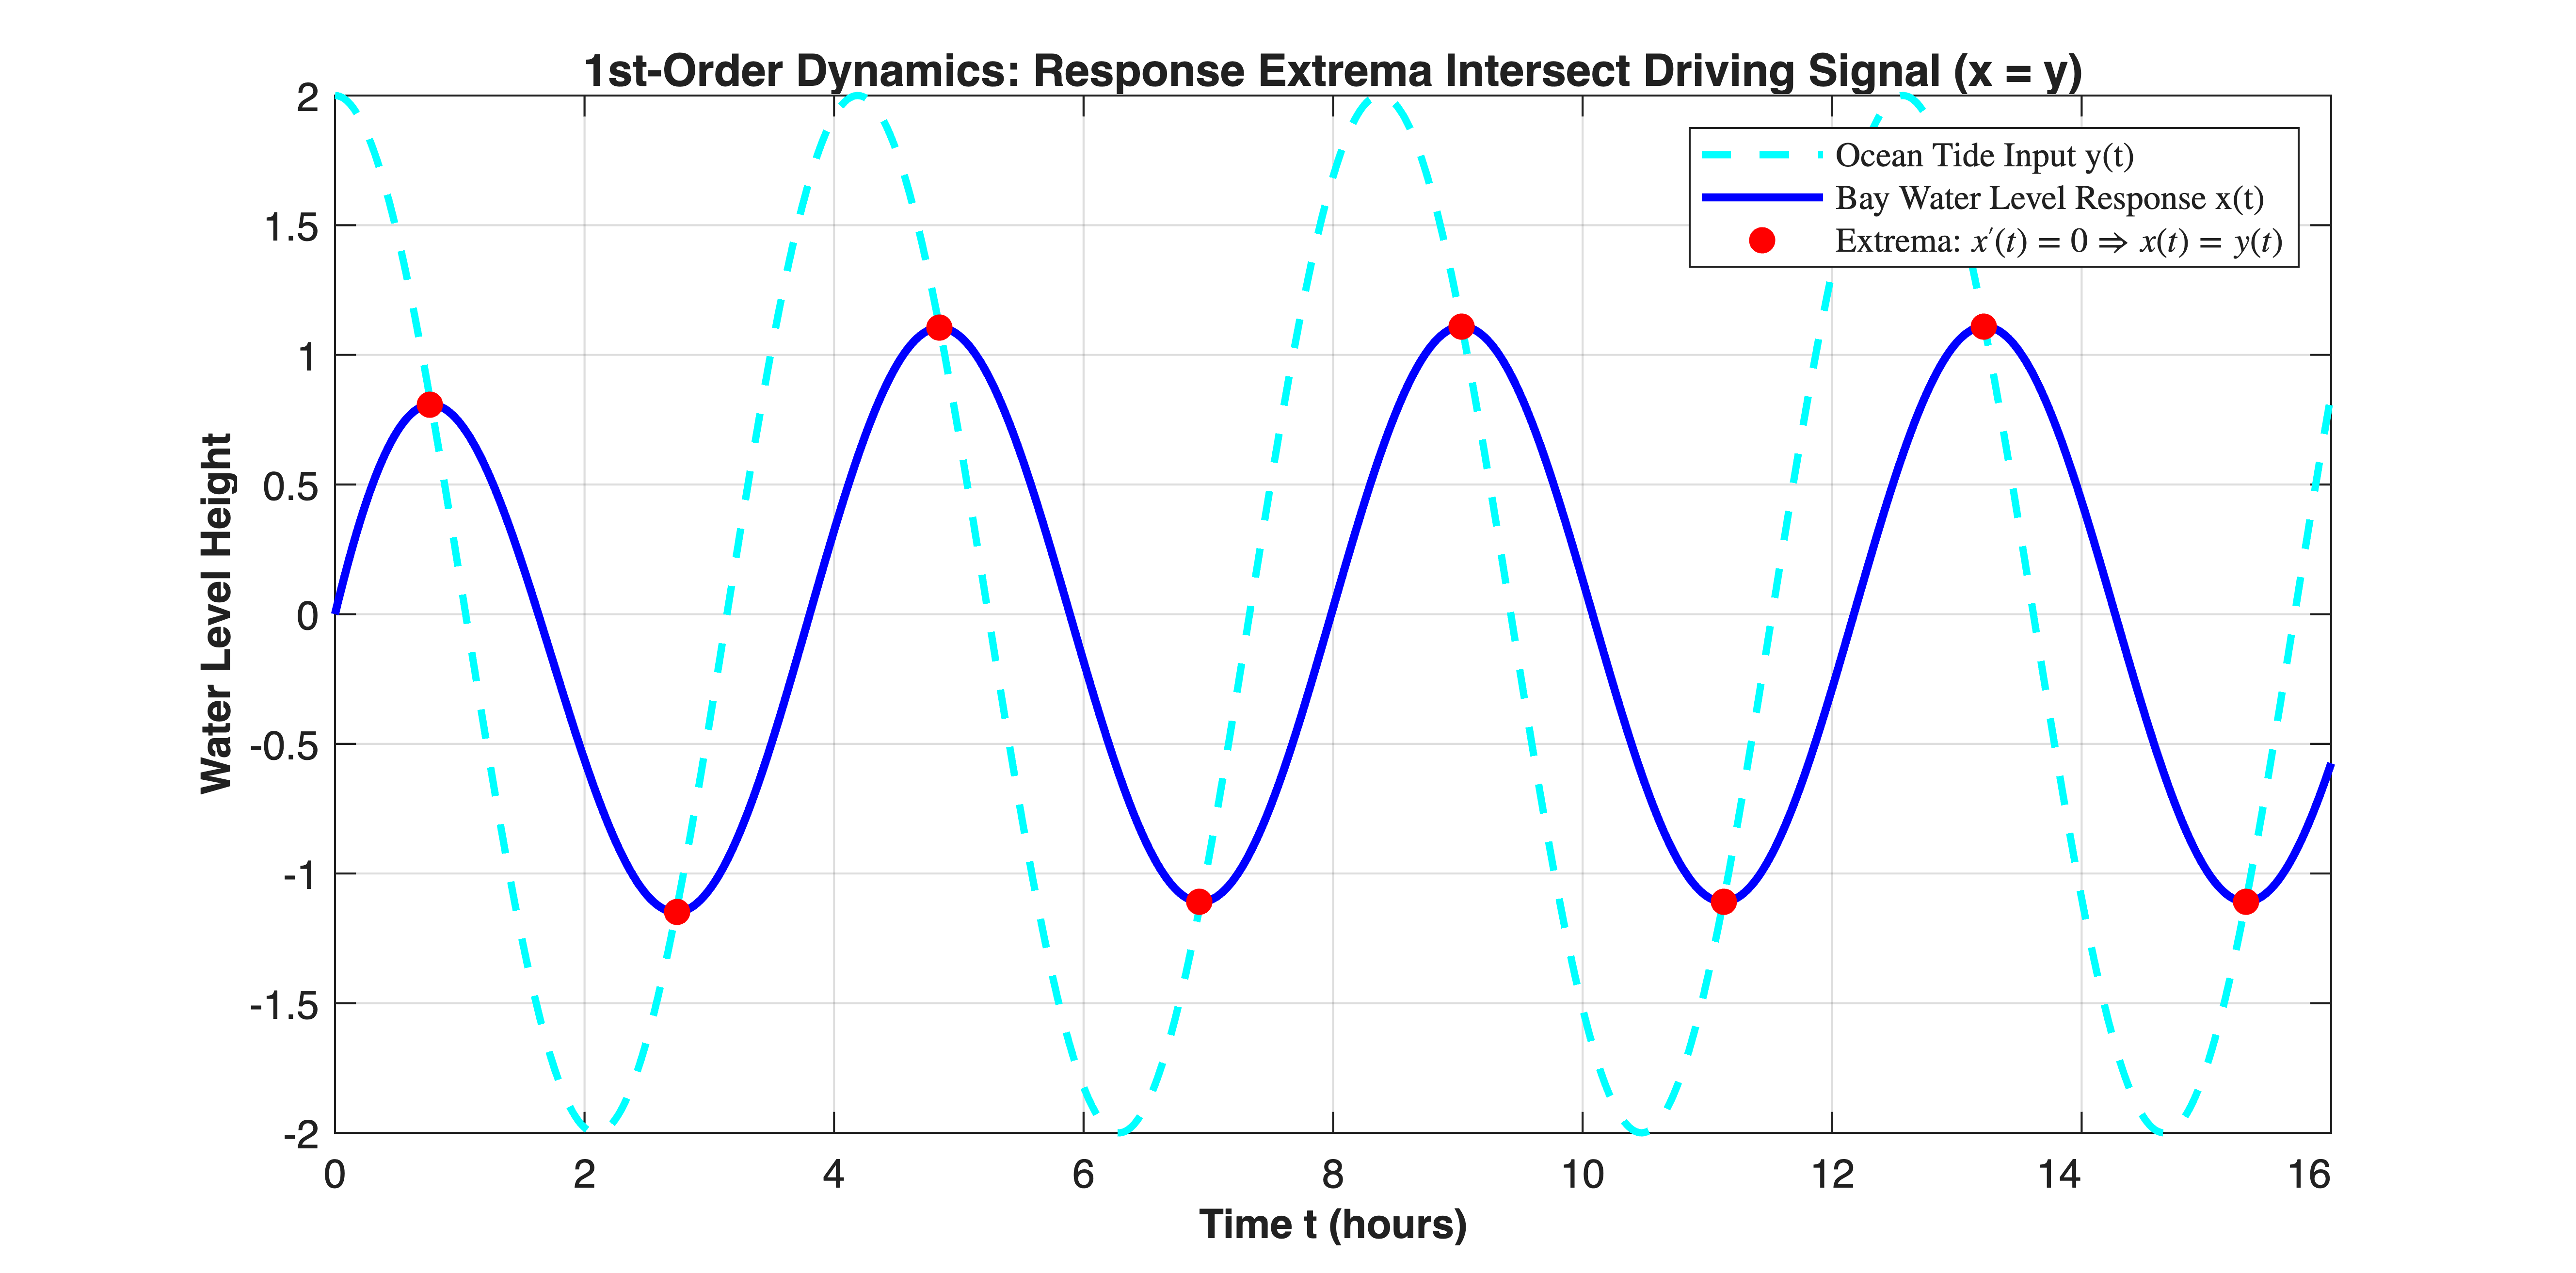

In [8]:


%% =========================================================================
%% Part 2: First-Order Tidal System Simulation (Extrema Crossing Proof)
%% =========================================================================
% Model: x' + k*x = k*y(t), y(t) = A*cos(w*t)
k_tide = 1.0;
w_tide = 1.5;
A_tide = 2.0;


G_tide = tf(k_tide, [1, k_tide]); % G(s) = k / (s + k)
t_tide = linspace(0, 16, 800);
y_ocean = A_tide * cos(w_tide * t_tide);


% Simulate using Control System Toolbox lsim
[x_bay, ~] = lsim(G_tide, y_ocean, t_tide);


figure('Color', [1 1 1], 'Position', [150, 150, 850, 420]);
hold on; grid on; box on;


plot(t_tide, y_ocean, 'c--', 'LineWidth', 1.8, 'DisplayName', 'Ocean Tide Input y(t)');
plot(t_tide, x_bay,   'b-',  'LineWidth', 2.0, 'DisplayName', 'Bay Water Level Response x(t)');


% Find local extrema of x_bay to verify intersection condition x' = 0 -> x = y
[pks_max, locs_max] = findpeaks(x_bay, t_tide);
[pks_min, locs_min] = findpeaks(-x_bay, t_tide);


plot(locs_max, pks_max, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 6, ...
     'DisplayName', 'Extrema: $x''(t) = 0 \Rightarrow x(t) = y(t)$');
plot(locs_min, -pks_min, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 6, 'HandleVisibility', 'off');


xlabel('Time t (hours)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Water Level Height', 'FontSize', 10, 'FontWeight', 'bold');
title('1st-Order Dynamics: Response Extrema Intersect Driving Signal (x = y)', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5, 'Interpreter','latex');
xlim([0, 16]);